<a href="https://colab.research.google.com/github/AgentForgeWorkshop/Tutorials/blob/main/Tutorial1_frameworks/01a_what_is_an_agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial 1A: What is an agent?

**AgentForge Workshop · Tutorial 1, notebook A of 2 · about 25 minutes**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AgentForgeWorkshop/Tutorials/blob/main/Tutorial1_frameworks/01a_what_is_an_agent.ipynb)

In the slides, an agent was **an LLM running in a loop, plus a harness that builds the context
and runs the tools.** In this notebook you will see that idea in code:

> Send the conversation **plus a list of tool descriptions** to the LLM.
> If it replies asking to call a tool, **run that Python function**, add the result to the
> conversation, and call the LLM again. Stop when it replies with plain text.

You will write that loop yourself in about twenty lines, and then see the same agent in three
frameworks: **LangChain** (built on **LangGraph**), **Pydantic AI** and **DeepAgents**.
Every framework is "the loop, plus conveniences".

| Step | What | Min |
|---|---|---|
| 0 | Setup | 3 |
| 1 | A bare LLM fails at a literature question | 2 |
| 2 | A tool is just a Python function | 4 |
| 3 | **The loop**, written by hand | 6 |
| 4 | The same agent in LangChain, and the LangGraph inside it | 4 |
| 5 | The same agent in Pydantic AI, returning a table | 3 |
| 6 | DeepAgents: the same loop with a bigger harness | 3 |

**Notebook B** then builds the same task as an LLM call, a workflow, an agentic workflow and
an agent, and compares them.

---
## Step 0: Setup

Run the next cell once. It takes about a minute. A warning about "pip dependency
google-colab" is expected and harmless.

In [1]:
%pip install -q "langchain==1.4.2" "langchain-google-genai==4.4.0" \
               "langchain-openai==1.6.2" "deepagents==0.7.16" "pydantic-ai==2.46.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.7/163.7 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.6/81.6 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.8/125.8 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 328.6/328.6 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.9/105.9 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 56.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 573.3/573.3 kB 35.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2

### Your API key

1. Open <https://openrouter.ai/keys> and create a key (the workshop gives you credit).
2. In Colab, click the **🔑 key icon** in the left sidebar (Secrets).
3. Add a secret named exactly `OPENROUTER_API_KEY`, paste your key, and turn on
   **Notebook access**.

A key pasted into a cell gets saved into the notebook, and notebooks get shared. Treat an API
key like a password.

In [3]:
import getpass
import os

from langchain.chat_models import init_chat_model


def get_key(name: str) -> str:
    """Read an API key from Colab's Secrets panel, or ask for it if there is none."""
    try:
        from google.colab import userdata

        return userdata.get(name)
    except Exception:  # not in Colab, or that secret is not set
        return os.environ.get(name) or getpass.getpass(f"{name}: ")


PROVIDER = "openrouter"  # <-- "openrouter" or "google"

if PROVIDER == "openrouter":
    # Any id from https://openrouter.ai/models that supports tool calling ("Tools" filter).
    OPENROUTER_MODEL = "deepseek/deepseek-v4.1-flash"
    os.environ["OPENROUTER_API_KEY"] = get_key("OPENROUTER_API_KEY")
    MODEL_NAME = f"openai:{OPENROUTER_MODEL}"  # OpenRouter speaks the OpenAI API
    model = init_chat_model(
        MODEL_NAME,
        temperature=0,
        base_url="https://openrouter.ai/api/v1",
        api_key=os.environ["OPENROUTER_API_KEY"],
    )
    PAI_MODEL = f"openrouter:{OPENROUTER_MODEL}"  # the same model, spelled for Pydantic AI

elif PROVIDER == "google":
    os.environ["GOOGLE_API_KEY"] = get_key("GOOGLE_API_KEY")
    MODEL_NAME = "google_genai:gemini-3.5-flash"
    model = init_chat_model(MODEL_NAME, temperature=0)
    PAI_MODEL = "google:gemini-3.5-flash"

print("Model ready:", MODEL_NAME)
print(model.invoke("Reply with exactly: ready").text)

Model ready: openai:deepseek/deepseek-v4.1-flash
ready


---
## Step 1: Why a bare LLM is not enough

This is the "chatbot" from the slides: text in, text out. Pick a topic you care about and ask
it for this week's papers.

In [4]:
TOPIC = "machine learning interatomic potentials for catalysis"  # <-- change me

answer = model.invoke(
    f"List 5 papers on '{TOPIC}' that were posted to arXiv in the last two weeks. "
    "Give the title, the authors and the arXiv link for each."
)
print(answer.text)

I can’t provide a verified list of arXiv papers from the last two weeks because I don’t have live web/arXiv access, and my training data does not cover 2026. I don’t want to fabricate titles, authors, or links.

To get exactly what you need, run this arXiv API query and filter for submissions between **2026-04-25 and 2026-05-09**:

```text
http://export.arxiv.org/api/query?search_query=all:%22machine+learning+interatomic+potential%22+AND+all:catalysis&start=0&max_results=50&sortBy=submittedDate&sortOrder=descending
```

You can also try related terms:

- `"machine learning interatomic potential" AND catalyst`
- `"MLIP" AND catalysis`
- `"neural network potential" AND catalysis`
- `"machine-learned potential" AND catalyst`

If you paste the arXiv results here, I can extract the **title, authors, and arXiv link** for 5 matching papers.


You get one of two things, and both make the point:

* **A refusal.** "I have no live access, my training data ends in…". Often it also guesses
  today's date wrong, because it has no way to know it.
* **Confident, plausible, unverifiable output.** Titles that sound real and arXiv IDs that
  may point to a different paper. This is how fake references end up in bibliographies.

The model is not lying: it has no connection to arXiv, it is completing text. **The fix is to
give it a way to look things up.** That is all a tool is.

---
## Step 2: A tool is just a Python function

`search_arxiv` is an ordinary function: no framework, no base class. It calls the public arXiv
API (no key needed) and returns a **string**, because a string is what we can put into a
conversation with an LLM.

One detail matters: arXiv treats each search term as a single word, so
`all:machine learning interatomic potentials` silently searches for "machine" and returns
near-random papers. `build_arxiv_query` ANDs the words together instead. Every data API has a
quirk like this: **the tool has to be right before the agent can be.**

In [5]:
import re
import textwrap
import urllib.parse
import urllib.request
import xml.etree.ElementTree as ET

ARXIV_API = "https://export.arxiv.org/api/query"
ATOM = {"atom": "http://www.w3.org/2005/Atom"}

# Words that add nothing to a search and would only narrow the results for no reason.
STOPWORDS = {"a", "an", "and", "are", "as", "at", "based", "by", "for", "from", "in",
             "into", "is", "of", "on", "or", "the", "to", "use", "using", "via", "with"}


def build_arxiv_query(topic: str) -> str:
    """Translate a plain-English topic into arXiv's query language (AND of the words)."""
    words = re.findall(r"[A-Za-z0-9][\w'-]*", topic)
    terms = [w for w in words if w.lower() not in STOPWORDS]
    return " AND ".join(f"all:{w}" for w in terms) or f"all:{topic}"


def search_arxiv(query: str, max_results: int = 5) -> str:
    """Search arXiv for recent papers and return their titles, authors, links and abstracts.

    Args:
        query: Search terms, e.g. 'graph neural network catalyst screening'.
        max_results: How many papers to return (1-10).
    """
    search_query = build_arxiv_query(query)
    params = urllib.parse.urlencode(
        {
            "search_query": search_query,
            "start": 0,
            "max_results": min(max_results, 10),
            "sortBy": "submittedDate",
            "sortOrder": "descending",
        }
    )
    with urllib.request.urlopen(f"{ARXIV_API}?{params}", timeout=30) as response:
        feed = ET.fromstring(response.read())

    papers = []
    for entry in feed.findall("atom:entry", ATOM):
        title = " ".join(entry.findtext("atom:title", "", ATOM).split())
        abstract = " ".join(entry.findtext("atom:summary", "", ATOM).split())
        authors = [a.findtext("atom:name", "", ATOM) for a in entry.findall("atom:author", ATOM)]
        papers.append(
            f"Title: {title}\n"
            f"Authors: {', '.join(authors[:3])}{' et al.' if len(authors) > 3 else ''}\n"
            f"Published: {entry.findtext('atom:published', '', ATOM)[:10]}\n"
            f"Link: {entry.findtext('atom:id', '', ATOM)}\n"
            f"Abstract: {textwrap.shorten(abstract, 1000, placeholder=' ...')}"
        )

    if not papers:
        # Telling the agent what we actually sent lets it retry with fewer terms.
        return (
            f"No papers found for '{query}' (sent to arXiv as: {search_query}). "
            "Try fewer or broader search terms."
        )
    return "\n\n---\n\n".join(papers)

In [6]:
# No LLM involved: it is an ordinary function, so just call it.
print("arXiv sees:", build_arxiv_query(TOPIC), "\n")
print(search_arxiv(TOPIC, max_results=2))

arXiv sees: all:machine AND all:learning AND all:interatomic AND all:potentials AND all:catalysis 

Title: BranchIP: Learning Adaptive Equivariant Computation for Interatomic Potentials
Authors: Laura Zichi, Gil Harari, Chuin Wei Tan et al.
Published: 2026-10-01
Link: http://arxiv.org/abs/2610.02013v1
Abstract: Equivariant machine learning interatomic potentials (MLIPs) have revolutionized atomistic modeling, but accurate treatment of complex materials and molecular systems demands expensive models. This limits simulation length- and time-scales, with tensor products a key computational bottleneck. The recent emergence of foundation-scale MLIPs further exacerbates this challenge. We present Branch Interatomic Potential (BranchIP), a single-model framework for learned adaptive tensor product computation, trained with a novel distillation loss. In our experiments on two systems of physical interest, a heterogeneous catalysis system and a proton-conducting solid acid electrolyte, BranchIP

### The model sees the docstring, never the body

A framework turns the function's **name, type hints and docstring** into a JSON description,
like step 1 on the "What a tool call looks like" slide. That description is all the model
knows about the tool. So a docstring is part of the prompt: **rewriting it is a real way to
change an agent's behaviour.**

In [7]:
import json

from langchain_core.utils.function_calling import convert_to_openai_tool

print(json.dumps(convert_to_openai_tool(search_arxiv), indent=2))

{
  "type": "function",
  "function": {
    "name": "search_arxiv",
    "description": "Search arXiv for recent papers and return their titles, authors, links and abstracts.",
    "parameters": {
      "properties": {
        "query": {
          "description": "Search terms, e.g. 'graph neural network catalyst screening'.",
          "type": "string"
        },
        "max_results": {
          "default": 5,
          "description": "How many papers to return (1-10).",
          "type": "integer"
        }
      },
      "required": [
        "query"
      ],
      "type": "object"
    }
  }
}


---
## Step 3: The loop

This is the centre of the tutorial. It is the loop from the slides, in Python:

```text
context = [system prompt, your request]          # 1. build the context
repeat:
    reply = LLM(context, tools=[search_arxiv])   # 2. the LLM decides
    if reply has no tool calls: return reply     #    done -> answer
    for each tool call in reply:
        result = run the Python function         # 3. the harness runs the tool
        context.append(result)                   #    and adds the result
```

Two things that surprise people:

* **The LLM never runs any code.** It writes a *request*: a tool name and some JSON
  arguments. Your code runs the function. That is your safety boundary: an agent can only do
  what its tools let it do.
* **The model has no memory between calls.** The `messages` list *is* the context, and it is
  resent in full at every step. That is why long runs get slow and expensive.

We print each step the way the slides read a trace: **Thought → Action → Observation.**

In [8]:
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage

TOOLS = {"search_arxiv": search_arxiv}

SYSTEM_PROMPT = (
    "You are a research assistant for a scientist. "
    "Use the search_arxiv tool to find real papers before answering. "
    "If a search finds nothing, try again with fewer, broader terms. "
    "Never invent titles, authors or links: report only what the tool returned, "
    "and always include the link for every paper you mention."
)


def observation(result: str) -> str:
    """A one-line summary of a tool result, for the trace."""
    if result.startswith("No papers found"):
        return "0 papers"
    if result.startswith("Title:"):
        return f"{result.count('Title:')} papers"
    return textwrap.shorten(result, 100)  # some other tool


def run_agent(question: str, max_steps: int = 6) -> str:
    """The whole agent, in about twenty lines."""
    llm = model.bind_tools(list(TOOLS.values()))         # show the model which tools exist
    messages = [SystemMessage(SYSTEM_PROMPT), HumanMessage(question)]  # 1. build the context

    for step in range(1, max_steps + 1):
        reply = llm.invoke(messages)                     # 2. the LLM decides
        messages.append(reply)
        if reply.text.strip() and reply.tool_calls:
            print(f"[{step}] Thought:     {textwrap.shorten(reply.text, 120)}")

        if not reply.tool_calls:                         #    no tool call -> done
            print(f"[{step}] Final answer\n")
            return reply.text

        for call in reply.tool_calls:                    # 3. the harness runs each tool
            print(f"[{step}] Action:      {call['name']}({call['args']})")
            result = TOOLS[call["name"]](**call["args"])
            print(f"[{step}] Observation: {observation(result)}")
            messages.append(ToolMessage(content=result, tool_call_id=call["id"]))
                                                         #    ... and round again
    return "Stopped: hit max_steps without a final answer."

In [9]:
print(run_agent(f"What are 3 recent papers on {TOPIC}? Summarise each in one sentence."))

[1] Thought:     I'll search arXiv for recent papers on this topic.
[1] Action:      search_arxiv({'query': 'machine learning interatomic potentials catalysis', 'max_results': 10})
[1] Observation: 10 papers
[1] Action:      search_arxiv({'query': 'machine learning potential catalyst surface reaction', 'max_results': 10})
[1] Observation: 10 papers
[2] Final answer

Here are three recent arXiv papers on machine learning interatomic potentials (MLIPs) for catalysis:

1. **Assessing the Transferability of General-Purpose Machine Learning Interatomic Potentials for Heterogeneous Catalysis with HetCat26** — Peuch, Kler-Young, Niu et al. (2026-09-24)
Introduces the HetCat26 benchmark suite and shows, across fifteen foundation MLIPs, that performance on general materials benchmarks poorly predicts accuracy on heterogeneous catalysis tasks such as surface energetics, adsorption, and reaction networks.
[http://arxiv.org/abs/2609.30621v1](http://arxiv.org/abs/2609.30621v1)

2. **Systematic Fine

### When the first try fails

The demo in the slides searched, got **0 results**, and broadened the query by itself. Let us
make that happen: ask for a search that is far too specific. Watch the trace, not the answer.

In [10]:
NARROW = "graphene oxide interlayer humidity stability perovskite tandem solar cell machine learning"

print(run_agent(
    f"Search arXiv for exactly this phrase first: '{NARROW}'. "
    "Then tell me about 2 recent papers on the topic."
))

[1] Thought:     I'll start with the exact phrase search as requested.
[1] Action:      search_arxiv({'query': 'graphene oxide interlayer humidity stability perovskite tandem solar cell machine learning'})
[1] Observation: 0 papers
[2] Thought:     The exact phrase returned nothing (arXiv treats it as a strict AND of all 11 terms, which is too narrow). Let me [...]
[2] Action:      search_arxiv({'query': 'graphene oxide perovskite solar cell stability', 'max_results': 6})
[2] Observation: 3 papers
[2] Action:      search_arxiv({'query': 'machine learning perovskite tandem solar cell', 'max_results': 6})
[2] Observation: 1 papers
[3] Final answer

## Result of the exact-phrase search

The exact phrase search returned **no papers**. arXiv parsed it as a strict AND across all 11 terms (`all:graphene AND all:oxide AND all:interlayer AND all:humidity AND ... AND all:learning`), which is far too restrictive — no single paper matches all of those terms at once. I therefore broadened the query

Nobody wrote "if empty, retry" in `run_agent`. The tool said *"No papers found… try broader
terms"*, that text went back into the context, and the model chose a new query. **The model
decides the next step**: that is what makes this an agent and not a script.

Things you controlled, which every framework also gives you:

* **`max_steps`**: without a step limit, a confused model can loop forever, and every lap
  costs money.
* **The system prompt**: "Never invent titles" is doing real work.
* **Error handling**: if `search_arxiv` raises (network hiccup), this cell dies. A framework
  catches the error and hands it to the model as the tool result, so it can try again.

---
## Step 4: The same agent in LangChain

`create_agent(model, tools, system_prompt)` builds the loop you just wrote.

In [11]:
from langchain.agents import create_agent

agent = create_agent(model, tools=[search_arxiv], system_prompt=SYSTEM_PROMPT)

result = agent.invoke(
    {"messages": [HumanMessage(f"What are 3 recent papers on {TOPIC}? One sentence each.")]}
)
print(result["messages"][-1].text)

Here are three recent papers on machine learning interatomic potentials (MLIPs) for catalysis:

1. **Assessing the Transferability of General-Purpose Machine Learning Interatomic Potentials for Heterogeneous Catalysis with HetCat26** (Peuch, Kler-Young, Niu et al., 2026) — Introduces a benchmark suite (HetCat26) covering surface energetics, metal–metal oxide interactions, adsorption, and reaction networks, and finds that performance on general materials benchmarks is only weakly predictive of transferability to heterogeneous catalysis across fifteen foundation models. http://arxiv.org/abs/2609.30621v1

2. **Systematic Fine-Tuning of MACE Interatomic Potentials for Catalysis** (Karimitari, Clary, Vigil-Fowler et al., 2026) — Compares nine MLIPs trained from scratch versus fine-tuned from foundation models on 141 reactions (CO₂ reduction, propane dehydrogenation, hydrogen intercalation on Pd, and out-of-distribution OER on metal oxides), showing that from-scratch models benefit greatly f

`result["messages"]` is the same list you built by hand in Step 3. Print it as a trace:

In [12]:
def show_trace(result, width=300):
    """Print an agent run as Thought / Action / Observation."""
    for message in result["messages"]:
        kind = type(message).__name__
        text = (message.text or "").strip()
        if kind == "HumanMessage":
            print(f"You:         {textwrap.shorten(text, width)}")
        elif kind == "ToolMessage":
            print(f"Observation: {observation(text)}")
        elif message.tool_calls:
            if text:
                print(f"Thought:     {textwrap.shorten(text, width)}")
            for call in message.tool_calls:
                args = {k: textwrap.shorten(str(v), 60) for k, v in call["args"].items()}
                print(f"Action:      {call['name']}({args})")
        elif text:
            print(f"Answer:      {textwrap.shorten(text, width)}")


show_trace(result)

You:         What are 3 recent papers on machine learning interatomic potentials for catalysis? One sentence each.
Thought:     I'll search arXiv for recent papers on this topic.
Action:      search_arxiv({'query': 'machine learning interatomic potentials catalysis', 'max_results': '10'})
Action:      search_arxiv({'query': 'machine learning potential catalyst surface reaction', 'max_results': '10'})
Observation: 10 papers
Observation: 10 papers
Answer:      Here are three recent papers on machine learning interatomic potentials (MLIPs) for catalysis: 1. **Assessing the Transferability of General-Purpose Machine Learning Interatomic Potentials for Heterogeneous Catalysis with HetCat26** (Peuch, Kler-Young, Niu et al., 2026) — Introduces a [...]


### The LangGraph inside

`create_agent` returns a **LangGraph** graph. LangGraph describes a program as nodes (steps)
and edges (what runs next). Draw this one:

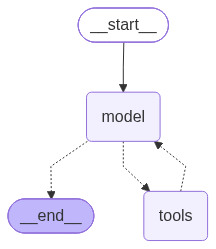

In [13]:
from IPython.display import Image, display


def draw(graph):
    """Draw a LangGraph graph (falls back to text if the drawing service is unreachable)."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())


draw(agent)

It is the loop from the slides: `model` → `tools` → back to `model`, until the model stops
calling tools and the run goes to `__end__`. In **notebook B** you will draw your own graphs
with LangGraph, including ones *without* that loop (workflows).

What did LangChain add over your twenty lines? A step limit, tool-error handling, one
interface for many model providers, streaming, and **middleware** to inspect or block a step,
which is how you add human approval (notebook B).

> ⚠️ Most LangChain tutorials online use the pre-1.0 API (`initialize_agent`,
> `AgentExecutor`, `LLMChain`). That API is gone. Look for `create_agent` in the
> [current docs](https://docs.langchain.com/oss/python/langchain/agents).

---
## Step 5: The same agent in Pydantic AI, returning a table

Prose is a poor deliverable for science: you usually want rows to sort, filter or hand to the
next script. [Pydantic AI](https://ai.pydantic.dev) is built around that. Describe the shape
you want as Pydantic classes, pass it as `output_type`, and the agent must return a validated
object. Same tool, same model, same loop, different framework.

In [14]:
from typing import List

from pydantic import BaseModel, Field


class Paper(BaseModel):
    title: str = Field(description="Exact title, copied from the search results")
    link: str = Field(description="arXiv link, copied verbatim from the search results")
    method: str = Field(description="The method or system studied, in one short phrase")
    key_finding: str = Field(description="One sentence, in the authors' own terms")
    relevance: int = Field(description="1 = tangential, 5 = directly on topic", ge=1, le=5)


class LiteratureTable(BaseModel):
    """A small literature table built only from real search results."""

    topic: str
    papers: List[Paper]

In [15]:
import pandas as pd
from pydantic_ai import Agent

os.environ["PYDANTIC_AI_NO_BANNER"] = "1"  # hide the start-up banner

pai_agent = Agent(
    PAI_MODEL,
    tools=[search_arxiv],            # the same plain function
    instructions=SYSTEM_PROMPT,
    output_type=LiteratureTable,     # the agent must return this shape
)

# Pydantic AI is async: `await` works at the top level of a Colab cell.
pai_result = await pai_agent.run(f"Build a literature table of 4 recent papers on {TOPIC}.")

print(pai_result.usage)  # requests, tokens: the cost of the run
df = pd.DataFrame([paper.model_dump() for paper in pai_result.output.papers])
df.to_csv("literature_table.csv", index=False)  # now it is just data
df

RunUsage(cache_read_tokens=3840, details={'is_byok': 0, 'audio_tokens': 0, 'reasoning_tokens': 559, 'image_tokens': 0}, input_tokens=9289, output_reasoning_tokens=559, output_tokens=1250, requests=3, tool_calls=3)


,title,link,method,key_finding,relevance
0,Assessing the Transferability of General-Purpo...,http://arxiv.org/abs/2609.30621v1,"HetCat26 benchmark suite (surface energetics, ...",Performance on existing general materials benc...,5
1,How accurate are foundational machine learning...,http://arxiv.org/abs/2512.16702v1,Systematic zero-shot evaluation of 80 foundati...,Current-generation foundational MLIPs can alre...,5
2,BranchIP: Learning Adaptive Equivariant Comput...,http://arxiv.org/abs/2610.02013v1,Branch Interatomic Potential: single-model fra...,BranchIP accelerates MLIPs by up to 2.4x and r...,5
3,Quantum-accurate atomistic modeling of enzyme ...,http://arxiv.org/abs/2609.09293v2,Machine-learned interatomic potential eSEN-omo...,The MLIP reproduces experimental barrier trend...,4


`pai_result.output` is a Python object, not text that looks like a table: a `relevance` of
`"very high"` would have been rejected, and the model asked to try again. Field descriptions
steer the model the same way tool docstrings do.

Note that `relevance` is the model's opinion, not a measurement. It is fine for sorting, not
for publishing.

*(LangChain can do this too, with `create_agent(..., response_format=LiteratureTable)`.)*

---
## Step 6: DeepAgents, the same loop with a bigger harness

The slides said **agent = LLM + harness**. `create_deep_agent` from
[DeepAgents](https://docs.langchain.com/oss/python/deepagents/overview) keeps the same LLM and
the same loop, and adds more harness: a **to-do list** it writes and updates while it works,
and a **file system** for drafts. You change one function name.

In [16]:
from deepagents import create_deep_agent

deep_agent = create_deep_agent(
    model=model,
    tools=[search_arxiv],
    system_prompt=(
        "You are a scientific literature analyst. Plan your work first, then search arXiv "
        "(several focused searches beat one broad one), and write your review to 'review.md' "
        "with the sections: Overview, Methods in use, Open questions, References. "
        "Cite only papers the search tool actually returned, with their links."
    ),
)

result = deep_agent.invoke(
    {"messages": [HumanMessage(f"Write a short review of recent work on {TOPIC}.")]}
)
show_trace(result, width=150)

You:         Write a short review of recent work on machine learning interatomic potentials for catalysis.
Thought:     I'll start by planning, then run several focused arXiv searches. **Plan:** 1. Search: ML interatomic potentials for catalysis / adsorbates on [...]
Action:      search_arxiv({'query': 'machine learning interatomic potentials heterogeneous [...]', 'max_results': '8'})
Action:      search_arxiv({'query': 'foundation machine learning interatomic potential [...]', 'max_results': '8'})
Action:      search_arxiv({'query': 'uncertainty quantification active learning machine [...]', 'max_results': '8'})
Action:      search_arxiv({'query': 'machine learning potential transition state reaction [...]', 'max_results': '8'})
Observation: 0 papers
Observation: 6 papers
Observation: 8 papers
Observation: 0 papers
Thought:     Two searches returned nothing (too many AND terms). Let me run narrower queries.
Action:      search_arxiv({'max_results': '8', 'query': 'machine learning inte

In [17]:
from pathlib import Path

# DeepAgents keeps its files in the run's state, not on disk. Print them, and save review.md.
for path, file in result.get("files", {}).items():
    print(f"========== {path} ==========")
    print(file["content"][:2000])
    out = Path(path.lstrip("/"))
    out.parent.mkdir(parents=True, exist_ok=True)
    out.write_text(file["content"], encoding="utf-8")

========== /review.md ==========
# Machine Learning Interatomic Potentials for Catalysis: A Short Review of Recent Work

## Overview

Machine learning interatomic potentials (MLIPs) have moved from proof-of-concept demonstrations on simple metals to the point where they are used to simulate realistic catalytic systems: supported nanoparticles, metal/oxide interfaces, electrified solid–liquid interfaces, and even whole enzymes in explicit solvent. The dominant driver of this shift is the arrival of *foundation* or *universal* MLIPs — large equivariant graph neural networks pretrained on broad materials datasets — which offer near-DFT accuracy out of the box and, crucially, serve as starting points for cheap downstream fine-tuning.

The central question in the catalysis literature is no longer "can an MLIP reproduce DFT?" but "does a general-purpose model transfer to catalytic problems?" The most direct answer comes from **HetCat26**, a benchmark of fifteen foundation models spanning sur

That run took longer and used many more tokens than Step 4: planning, several searches,
drafts. So:

| Your task | Reach for |
|---|---|
| One clear task, a few tools, an answer now | `create_agent` (LangChain) |
| You need a validated table or object back | Pydantic AI |
| Open-ended, multi-stage work (survey a field, compare ten methods) | `create_deep_agent` |

DeepAgents can also hand sub-questions to **sub-agents**: an agent orchestrating other
agents. That is a multi-agent system, the topic of **Tutorial 4**. Its file system is a form
of memory, the topic of **Tutorial 2**.

---
## Wrap-up

* An agent is **an LLM in a loop** with tools. You wrote one in twenty lines.
* **The harness** (your code or a framework) builds the context, runs the tools, and sets the
  limits. The model only writes requests.
* **Frameworks differ in conveniences, not in the idea:** LangChain/LangGraph (graphs,
  middleware), Pydantic AI (typed output), DeepAgents (planning and files).

Before you use this on real work (slide "Limitations and risks"): **verify every citation**,
**log runs and pin model versions**, **set step limits**, and **give tools the narrowest
permissions** that do the job.

**Next: notebook B**, where the same task is built as an LLM call, a workflow, an agentic
workflow and an agent.

### Take-home exercises

1. **Change the docstring.** Edit the `search_arxiv` docstring (for example, ask for queries
   of at most three words), re-run Step 3, and watch the Actions change.
2. **A second source.** Biology and medicine mostly live on PubMed, not arXiv. Finish
   `search_pubmed` below and give the agent both tools. Watch how it chooses a source, and
   remember that *your docstring* is what teaches it.

In [18]:
# Exercise 2: starter. NCBI E-utilities need no key; keep to 3 requests per second or fewer.
#   search:    {EUTILS}/esearch.fcgi?db=pubmed&retmode=json&term=...&retmax=...
#              -> PubMed IDs, under esearchresult.idlist
#   summarise: {EUTILS}/esummary.fcgi?db=pubmed&retmode=json&id=id1,id2
#              -> titles, journals and dates, under result.<id>
EUTILS = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils"


def search_pubmed(query: str, max_results: int = 5) -> str:
    """TODO: describe this tool for the model: what it searches, and what a good query is.

    Args:
        query: TODO
        max_results: TODO
    """
    raise NotImplementedError


# pubmed_agent = create_agent(model, tools=[search_arxiv, search_pubmed], system_prompt=SYSTEM_PROMPT)

---
*AgentForge Workshop, Tutorial 1A. Questions, fixes and better examples are welcome:
<https://github.com/AgentForgeWorkshop/Tutorials>*